## 01: Creating tomograms from L1C data and validating with pre-processed `tomcubes`

Outline

- **A.** Helper Functions
- **B.** Load the stack window and correct its phase
- **C.** Baselines: κz, vertical resolution, ambiguity
- **D.** Multi-baseline coherence matrices
- **E.** Tomograms: beamformer and Capon
- **F.** The workshop cube (TOM_L1D) at the same cells
- **G.** Height maps from both cubes (BPS TFH's rule)
- **H.** Quick Comparison with reference ALS


In [5]:
import os, re, time
from itertools import combinations
from pathlib import Path
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import netCDF4
import rasterio
from rasterio.windows import Window
from pyproj import Transformer
from scipy.ndimage import uniform_filter
from scipy.interpolate import RegularGridInterpolator
from scipy.signal import medfilt2d
from scipy.spatial import cKDTree
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)

In [ ]:
BIODATA_DIR = Path("...") # Specify yours
L1C_DIR = BIODATA_DIR / "data/work/biomass/amacayacu/l1c_sta"
WORKSHOP = BIODATA_DIR / "projects/biomass-tomo-gp/B_bps_eda/data/hackathon-data/extracted"

REF_DIR = Path("...") # Specify yours
ALS_CHM = REF_DIR / "data/reference/amacayacu/chm_lspikefree_Amacayacu.tif"
ALS_MASKS = REF_DIR / "data/reference/amacayacu/masks_Amacayacu.tif"

pd.set_option("display.width", 200)

#### A. Helper Functions

In [7]:
cycle = lambda d: re.search(r"_(C\d\d)_T", d.name).group(1)
own_annot = lambda d: next((d / "annotation_coregistered").glob("*annot.xml"))
lut_file = lambda d: next((d / "annotation_coregistered").glob("*lut.nc"))


def first(v):
    return v[0] if isinstance(v, list) else v


def annot(xml):
    """Metadata for per-pass and primary image reference"""
    out = {}
    for el in ET.parse(xml).iter():
        t = (el.text or "").strip()
        if t and len(el) == 0:
            out.setdefault(el.tag.split("}")[-1], []).append(t)
    return {k: v[0] if len(v) == 1 else v for k, v in out.items()}


def read_lut(d, group, var):
    """Fetch specific parameters for core groups (geometry, coregistration, skpPhaseCalibration, interferometry, etc.)"""
    with netCDF4.Dataset(lut_file(d)) as f:
        x = np.ma.filled(f[group][var][:].astype("float64"), np.nan)
        ax = np.asarray(f["relativeAzimuthTime"][:]), np.asarray(f["slantRangeTime"][:])
    x[x == -9999] = np.nan
    return x, ax

def als_bbox():
    with rasterio.open(ALS_CHM) as s:
        b, crs = s.bounds, s.crs
    xs, ys = Transformer.from_crs(crs, 4326, always_xy=True).transform([b.left, b.right] * 2, [b.bottom] * 2 + [b.top] * 2)
    return min(xs), min(ys), max(xs), max(ys)

In [8]:
is_primary = lambda d: abs(float(annot(own_annot(d)).get("normalBaseline", 0))) < 1e-3

def l1c_window(d, lon_min, lat_min, lon_max, lat_max, margin_m=1500.0):
    """Fetch rows/cols of L1C covering a lat/lon bbox with a margin its LUT geometry."""
    
    a = annot(own_annot(d))
    dt_az, dt_rg, rg0 = float(a["azimuthTimeInterval"]), float(a["rangeTimeInterval"]), float(a["firstSampleSlantRangeTime"])
    ny, nx = int(a["numberOfLines"]), int(a["numberOfSamples"])

    # Geolocation from the LUT with margin scaled in degrees
    lat, (ta, tr) = read_lut(d, "geometry", "latitude")
    lon, _ = read_lut(d, "geometry", "longitude")
    dlat = margin_m / 111_320.0
    dlon = dlat / np.cos(np.deg2rad(0.5 * (lat_min + lat_max)))

    ia, ir = np.where((lat >= lat_min - dlat) & (lat <= lat_max + dlat) & (lon >= lon_min - dlon) & (lon <= lon_max + dlon))
    pa, pr = np.diff(ta).mean(), np.diff(tr).mean()
    clip = lambda v, n: int(np.clip(round(v), 0, n))
    
    return ((clip((ta[ia].min() - pa) / dt_az, ny), clip((ta[ia].max() + pa) / dt_az, ny)),
            (clip((tr[ir].min() - pr - rg0) / dt_rg, nx), clip((tr[ir].max() + pr - rg0) / dt_rg, nx)))


def load_stack(dirs, win):
    """Fetches SLC window of each pass (pass, pol HH HV VH VV, az, rg), 
    its flattening and SKP screens and κz on the window grid, and the primary's geometry there.
    """

    # Setting window and image grid for co-registration of all passes
    (r0, r1), (c0, c1) = win
    a = annot(own_annot(dirs[0]))
    dt_az, dt_rg, rg0 = float(a["azimuthTimeInterval"]), float(a["rangeTimeInterval"]), float(a["firstSampleSlantRangeTime"])
    grid = tuple(np.meshgrid(np.arange(r0, r1) * dt_az, rg0 + np.arange(c0, c1) * dt_rg, indexing="ij"))

    # Bilinear interpolation of coarse LUT nodes onto window pixels
    def on_win(d, g, v):
          x, ax = read_lut(d, g, v)
          return RegularGridInterpolator(ax, x, bounds_error=False, fill_value=np.nan)(grid)

    # Main Stack data definition
    S = dict(
        U0=[],    # raw coregistered SLC
        flat=[],  # flattening phase per screen
        skp=[],   # SKP calibration phase per screen
        K=[],     # vertical wavenumber
        cycles=[cycle(d) for d in dirs], 
        dirs=dirs, 
        win=win,
        az_spacing_m=float(a["azimuthPixelSpacing"]), 
        slant_spacing_m=float(a["rangePixelSpacing"])
    )
    
    for d in dirs:
        fa, fp = (next((d / "measurement").glob(f"*i_{k}.tif*")) for k in ("abs", "phase"))
        with rasterio.open(fa) as sa, rasterio.open(fp) as sp:
            amp, pha = (s.read(window=Window(c0, r0, c1 - c0, r1 - r0)).astype("float32") for s in (sa, sp))
        s = (amp * np.exp(1j * pha)).astype("complex64")
        s[(amp == -9999) | (pha == -9999)] = np.nan
        S["U0"].append(s)

        # No screens removed for primary image
        prim = is_primary(d)
        S["flat"].append(0 if prim else on_win(d, "coregistration", "flatteningPhaseScreen"))
        S["skp"].append(0 if prim else on_win(d, "skpPhaseCalibration", "skpCalibrationPhaseScreen"))
        S["K"].append(np.zeros(s.shape[1:]) if prim else on_win(d, "coregistration", "waveNumbers"))
        
        if prim:
            S["primary"] = cycle(d)
            for k, (g, v) in dict(lat=("geometry", "latitude"), lon=("geometry", "longitude"), inc=("geometry", "incidenceAngle"),
                                  slope=("geometry", "rangeTerrainSlope")).items():
                S[k] = on_win(d, g, v)
    for k in ("U0", "K"):
        S[k] = np.stack(S[k])
    S["flat"] = np.stack([np.broadcast_to(x, S["K"].shape[1:]) for x in S["flat"]])
    S["skp"] = np.stack([np.broadcast_to(x, S["K"].shape[1:]) for x in S["skp"]])
    return S

### B. L1C Stack: Loading, Phase Correction, Pair Interferometric Coherence

Each L1C is already coregistered to the primary pass (C04). Two phase screens from each pass's LUT are applied:

- **phase flattening** with `dem_phases`
- **SKP calibration** for residual phase disturbance

$u_n = s_n \cdot \exp(+i(\phi^{flat}_n + \phi^{skp}_n))$. The SKP screen enters with + where the practical's calibration phase enters with −: a sign convention of the screens.
After this, each pass's phase is $\phi_n \approx k_{z,n}\, z$.

`WIN` used for this analysis is a buffered area (1.5km outward) around the selected AOI with reference (eg. Amacayacu or other)

In [9]:
DIRS = sorted(L1C_DIR.glob("BIO_S1_STA__1S_*_M02_C0?_T029_F001_*"), key=cycle)
prim_dir = next(d for d in DIRS if cycle(d) == "C04")
WIN = l1c_window(prim_dir, *als_bbox())

S = load_stack(DIRS, WIN)

# flattened + calibrated
U = S["U0"] * np.exp(1j * (S["flat"] + S["skp"]))[:, None]            
K = S["K"] # wave numbers
n = len(DIRS)

print(f"{n} passes {S['cycles']}, primary {S['primary']}") 
print(f"Window rows {WIN[0]} cols {WIN[1]}")
print(f"U {U.shape} (pass, pol, az, rg)")

7 passes ['C01', 'C02', 'C03', 'C04', 'C05', 'C06', 'C07'], primary C04
Window rows (15168, 16416) cols (612, 830)
U (7, 4, 1248, 218) (pass, pol, az, rg)


Quick look at the Pauli RGB decomposition of the 7 passes

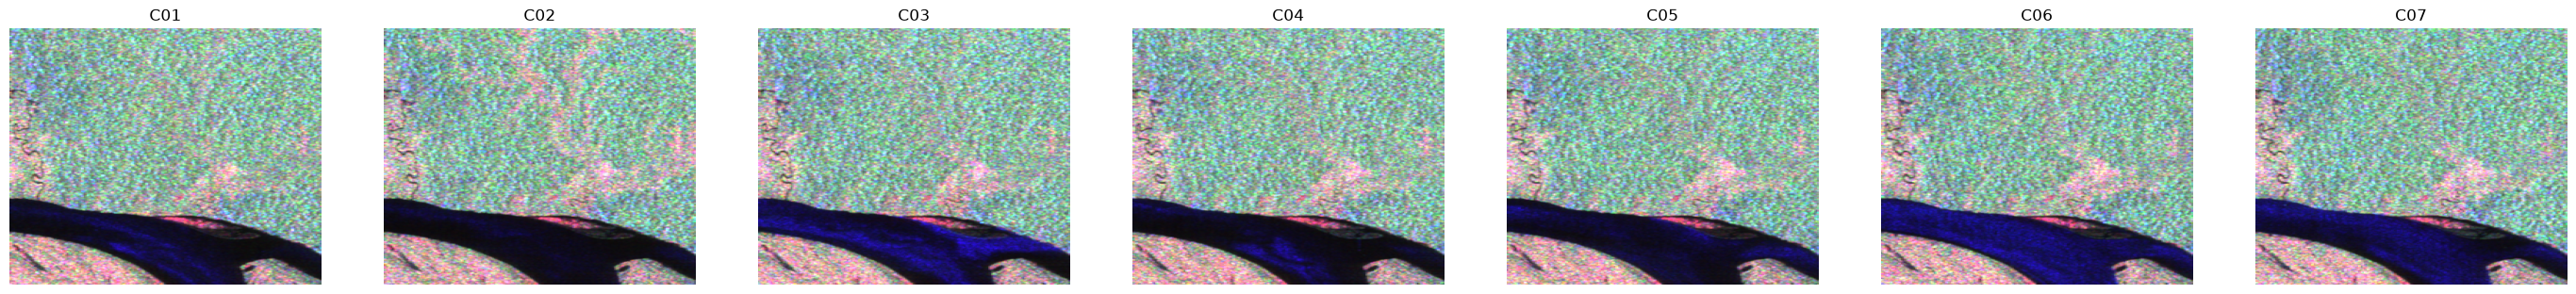

In [10]:
inc_mean = np.deg2rad(np.nanmean(S["inc"]))
ASPECT = S["az_spacing_m"] / (S["slant_spacing_m"] / np.sin(inc_mean))
look = lambda x, w=(7, 2): uniform_filter(x, w)

fig, axs = plt.subplots(1, n, figsize=(5 * n, 7))
for i, ax in enumerate(axs):
    hh, hv, vh, vv = np.nan_to_num(S["U0"][i])
    rgb = np.stack([look(abs(hh - vv) ** 2), look(abs(hv + vh) ** 2), look(abs(hh + vv) ** 2)], -1)
    ax.imshow(np.clip(np.sqrt(rgb / np.percentile(rgb, 98, axis=(0, 1))), 0, 1), aspect=ASPECT)
    ax.set_title(S["cycles"][i]); ax.axis("off")
plt.show()

- **coherence** $\Gamma_{nm} = \frac{E[s_n s^*_m]}{\sqrt{E[|s_n|^2]\,E[|s_m|^2]}}$ 
- **covariance** $E[s_n s^*_m]$

In [11]:
def window_px(size_m):
    """(azimuth, range) pixels of a size_m x size_m ground window."""
    return int(np.ceil(size_m / S["az_spacing_m"])), int(np.ceil(size_m * np.sin(inc_mean) / S["slant_spacing_m"]))


def coherence(s1, s2, w):
    s1, s2 = np.nan_to_num(s1).astype(complex), np.nan_to_num(s2).astype(complex)
    return uniform_filter(s1 * s2.conj(), w) / np.sqrt(uniform_filter(abs(s1) ** 2, w) * uniform_filter(abs(s2) ** 2, w))

Comparing coherence computation with flattening and SKP correction

In [12]:
w150 = window_px(150) # Similar to tomocube window 
a_, b_ = 2, 3 # Passes: C03, C04 (primary)

cases = {
    "no correction": 0, 
    "flattening": S["flat"][a_], 
    "flattening + SKP": S["flat"][a_] + S["skp"][a_]
}

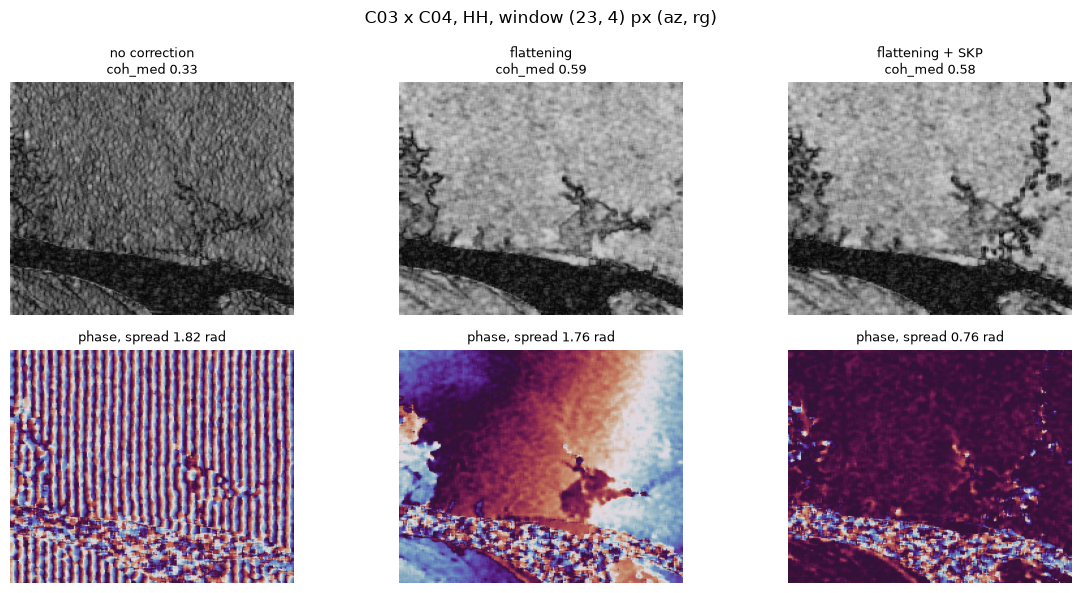

In [13]:
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
for j, (lab, ph) in enumerate(cases.items()):
    g = coherence(S["U0"][a_, 0] * np.exp(1j * ph), S["U0"][b_, 0], w150)
    axs[0, j].imshow(abs(g), vmin=0, vmax=1, cmap="gray", aspect=ASPECT); axs[0, j]
    axs[0, j].set_title(f"{lab}\ncoh_med {np.nanmedian(abs(g)):.2f}", fontsize=9)
    
    axs[1, j].imshow(np.angle(g), vmin=-np.pi, vmax=np.pi, cmap="twilight", aspect=ASPECT)
    axs[1, j].set_title(f"phase, spread {np.nanstd(np.angle(g)):.2f} rad", fontsize=9)

for ax in axs.flat: 
    ax.axis("off")

plt.suptitle(f"C03 x C04, HH, window {w150} px (az, rg)")
plt.tight_layout()
plt.show()

### C. Baselines

- One pass every 3 days, with wave number proportional to the perpendicular baseline.
- **Rayleigh resolution** $\Delta z = 2\pi / (k_{z,max} - k_{z,min})$: set by the κz span.
- **Ambiguity height** $2\pi / \overline{\Delta k_z}$: the beamformer repeats this far up.

In [14]:
def vertical_resolution(Kc, sel):
    """Rayleigh resolution 2π / (κz_max - κz_min) of a pass subset, per cell [m]."""
    k = Kc[..., list(sel)]
    return 2 * np.pi / (np.nanmax(k, -1) - np.nanmin(k, -1))

In [15]:
dates = pd.to_datetime([re.search(r"_(\d{8})T", d.name).group(1) for d in DIRS])
days = (dates - dates[0]).days.values
kz_med = np.nanmedian(K.reshape(n, -1), 1)
Kw = K.transpose(1, 2, 0)

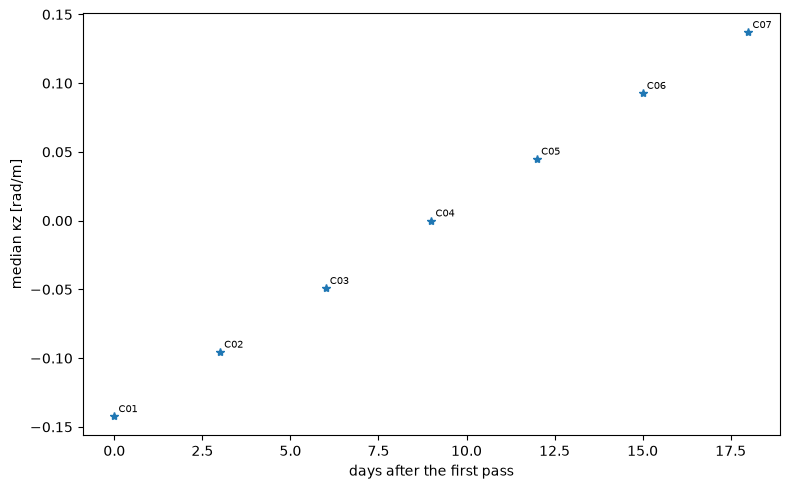

κz steps [rad/m]: [0.0469 0.0463 0.0491 0.045  0.0478 0.0443] → ambiguity height 135 m


,subsets,best_dz_m,worst_dz_m
3 passes,35.0,22.5,68.2
5 passes,21.0,22.5,33.7
7 passes,1.0,22.5,22.5


In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(days, kz_med, "*")
for i, c in enumerate(S["cycles"]):
    ax.annotate(c, (days[i], kz_med[i]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("days after the first pass"); ax.set_ylabel("median κz [rad/m]"); plt.tight_layout(); plt.show()

step = np.diff(kz_med)
print("κz steps [rad/m]:", np.round(step, 4), f"→ ambiguity height {2 * np.pi / step.mean():.0f} m")
pd.DataFrame({f"{k} passes": dict(subsets=len(dz := [np.nanmedian(vertical_resolution(Kw, s)) for s in combinations(range(n), k)]),
                                  best_dz_m=min(dz), worst_dz_m=max(dz)) for k in (3, 5, n)}).T.round(1)

### D. Multi-baseline coherence matrices

In [17]:
def pol_image(U, pol):
    i = {"HH": 0, "HV": 1, "VH": 2, "VV": 3}
    X = (U[:, 1] + U[:, 2]) / 2 if pol == "XP" else U[:, i[pol]]
    return np.nan_to_num(X).astype(np.complex128)


def covariance_matrix(X, w, rows, cols, normalise=True):
    """N x N matrix of pol image X (pass, az, rg) at cells rows x cols"""
    E = lambda a: uniform_filter(a, w)[np.ix_(rows, cols)]
    pw = [E(abs(X[a]) ** 2).real for a in range(len(X))]
    G = np.empty((len(rows), len(cols), len(X), len(X)), np.complex128)
    for a in range(len(X)):
        for b in range(a, len(X)):
            c = E(X[a] * X[b].conj())
            if normalise:
                c = c / np.sqrt(pw[a] * pw[b])
            G[..., a, b], G[..., b, a] = c, np.conj(c)
    return G

In [18]:
az_sub = np.arange(0, U.shape[2], int(100 / S["az_spacing_m"]))
rg_sub = np.arange(0, U.shape[3], int(100 * np.sin(inc_mean) / S["slant_spacing_m"]))
ix = np.ix_(az_sub, rg_sub)
Kc = K[:, az_sub][:, :, rg_sub].transpose(1, 2, 0)                  # κz at the cells (az cell, rg cell, pass)
lat_c, lon_c, slope_c, inc_c = S["lat"][ix], S["lon"][ix], np.deg2rad(S["slope"][ix]), np.deg2rad(S["inc"][ix])
data_cells = np.isfinite(lat_c) & (abs(np.nan_to_num(U[0, 0][ix])) > 0)

POLS = ("HH", "XP", "VV")
Gcoh = {p: covariance_matrix(pol_image(U, p), w150, az_sub, rg_sub, normalise=True) for p in POLS}
Gcov = {p: covariance_matrix(pol_image(U, p), w150, az_sub, rg_sub, normalise=False) for p in POLS}
print(f"cells {len(az_sub)} × {len(rg_sub)} · window {w150}px")

cells 90 × 109 · window (23, 4)px


In [ ]:
LADDER = {
    "CHM mean": np.mean, 
    **{f"CHM p{q}": (lambda q: lambda v: np.percentile(v, q))(q) for q in (50, 75, 90, 95, 98)}, 
    "CHM max": np.max
}

def als_cells(lat, lon, half_m=100.0):
    """CHM statistics (LADDER), canopy cover (> 5 m)"""
    with rasterio.open(ALS_CHM) as s:
        chm, tr, crs, res, nod = s.read(1).astype("float32"), s.transform, s.crs, s.res[0], s.nodata
    
    with rasterio.open(ALS_MASKS) as s:
        chm[(chm == nod) | (s.read(6) == 1)] = np.nan

    xs, ys = Transformer.from_crs(4326, crs, always_xy=True).transform(np.nan_to_num(lon.ravel()), np.nan_to_num(lat.ravel()))
    rr, cc = rasterio.transform.rowcol(tr, xs, ys)
    k = int(round(half_m / res))
    out = {key: np.full(lat.size, np.nan) for key in [*LADDER, "cover", "valid"]}

    for i, (r, c) in enumerate(zip(rr, cc)):
        if k <= r < chm.shape[0] - k and k <= c < chm.shape[1] - k:
            v = chm[r - k:r + k, c - k:c + k].ravel(); ok_ = np.isfinite(v)
            out["valid"][i] = ok_.mean()
            if ok_.sum() > 100:
                v = v[ok_]
                for key, f in LADDER.items():
                    out[key][i] = f(v)
                out["cover"][i] = np.mean(v > 5)
    return {key: x.reshape(lat.shape) for key, x in out.items()}

In [20]:
A = als_cells(lat_c, lon_c)
ref = {key: A[key] for key in LADDER}

TOP = "CHM p98"
ok = data_cells & (np.nan_to_num(A["valid"]) >= 0.8) # ALS filtered by 
print(f"ALS at {ok.sum()} cells (≥ 80 % usable)")

ALS at 1902 cells (≥ 80 % usable)


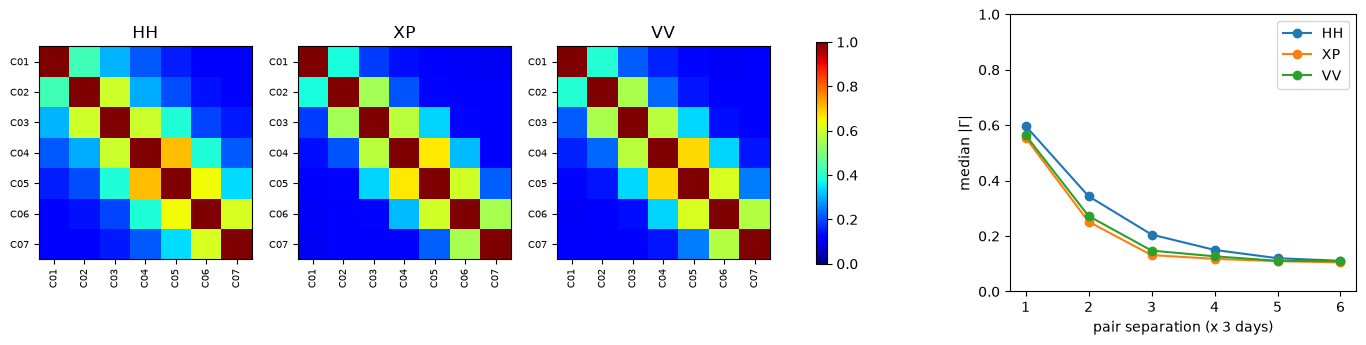

In [21]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.3]))
for a, p in zip(ax, POLS):
    med = np.nanmedian(abs(Gcoh[p][ok]), 0)
    im = a.imshow(med, vmin=0, vmax=1, cmap="jet"); a.set_title(p)
    a.set_xticks(range(n)); a.set_xticklabels(S["cycles"], rotation=90, fontsize=7); a.set_yticks(range(n)); a.set_yticklabels(S["cycles"], fontsize=7)
    ax[3].plot(range(1, n), [np.mean([med[i, i + g] for i in range(n - g)]) for g in range(1, n)], "o-", label=p)
ax[3].set_xlabel("pair separation (x 3 days)"); ax[3].set_ylabel("median |Γ|"); ax[3].set_ylim(0, 1); ax[3].legend()
fig.colorbar(im, ax=ax[:3], shrink=.8); plt.show()

### E. Tomograms: beamformer and Capon


$Tomo(z) = \mathbf{a}^H(z)\,\mathbf{s}$, steering vector $\{\mathbf{a}(z)\}_i = \exp(-j k_z^i z)/\sqrt{N}$. Multilooked and energy-normalised:

- **beamformer** (Fourier): $|Tomo(z)|^2 \cong \mathbf{a}^H(z)\,\hat{\Gamma}\,\mathbf{a}(z)$
- **Capon**: $T_{CP}(z) = \dfrac{1}{\mathbf{a}^H(z)\,\hat{\Gamma}^{-1}\,\mathbf{a}(z)}$, here with diagonal loading $\hat\Gamma + \varepsilon I$, ε = 10⁻³ × mean diagonal (the practical uses `d_load = 0`).


In [22]:
def steering(Kc, z):
    return np.exp(-1j * Kc[..., :, None] * z) / np.sqrt(Kc.shape[-1])


def tomograms(G, Kc, z, eps=1e-3, sel=None):
    """Beamformer aᴴ G a and Capon 1 / (aᴴ (G + εI)⁻¹ a) for every cell. G (..., N, N), Kc (..., N); sel: pass subset."""
    if sel is not None:
        sel = list(sel); G = G[..., sel, :][..., :, sel]; Kc = Kc[..., sel]
    N = Kc.shape[-1]
    A = steering(Kc, z)
    Gn = np.nan_to_num(G)
    bf = np.real(np.einsum("...iz,...ij,...jz->...z", A.conj(), Gn, A))
    tr = np.real(np.trace(Gn, axis1=-2, axis2=-1))[..., None]
    cp = 1 / np.real(np.einsum("...iz,...ij,...jz->...z", A.conj(), np.linalg.inv(Gn + eps * (tr / N)[..., None] * np.eye(N)), A))
    bad = ~np.isfinite(G).all(axis=(-1, -2)) | (tr[..., 0] <= 0)
    bf[bad] = cp[bad] = np.nan
    return bf, cp

In [23]:
norm = lambda P: P / np.nanmax(P, -1, keepdims=True)

z = np.arange(-60, 100.01, 2.0)
TOMO = {}
for p in POLS:
    TOMO[(p, "beamformer")], TOMO[(p, "Capon")] = tomograms(Gcoh[p], Kc, z)
    TOMO[(p, "beamformer, covariance")] = tomograms(Gcov[p], Kc, z)[0]
print({k: v.shape for k, v in TOMO.items() if k[0] == "XP"})

{('XP', 'beamformer'): (90, 109, 81), ('XP', 'Capon'): (90, 109, 81), ('XP', 'beamformer, covariance'): (90, 109, 81)}


Visualizing the Transect / cell rows with the most ALS coverage, (each column normalised to its peak):

In [24]:
def transect(ax, P, lines=None, title=None, ylim=(-30, 80)):
    ax.imshow(norm(P).T, origin="lower", aspect="auto", extent=[-.5, P.shape[0] - .5, z[0], z[-1]], cmap="jet", vmin=0, vmax=1)
    for lab, (y, fmt) in (lines or {}).items():
        ax.plot(y, fmt, lw=1.5, ms=4, label=lab)
    ax.axhline(0, c="w", lw=.5); ax.set_ylim(*ylim)
    ax.set_ylabel(f"{title}\nz [m]")

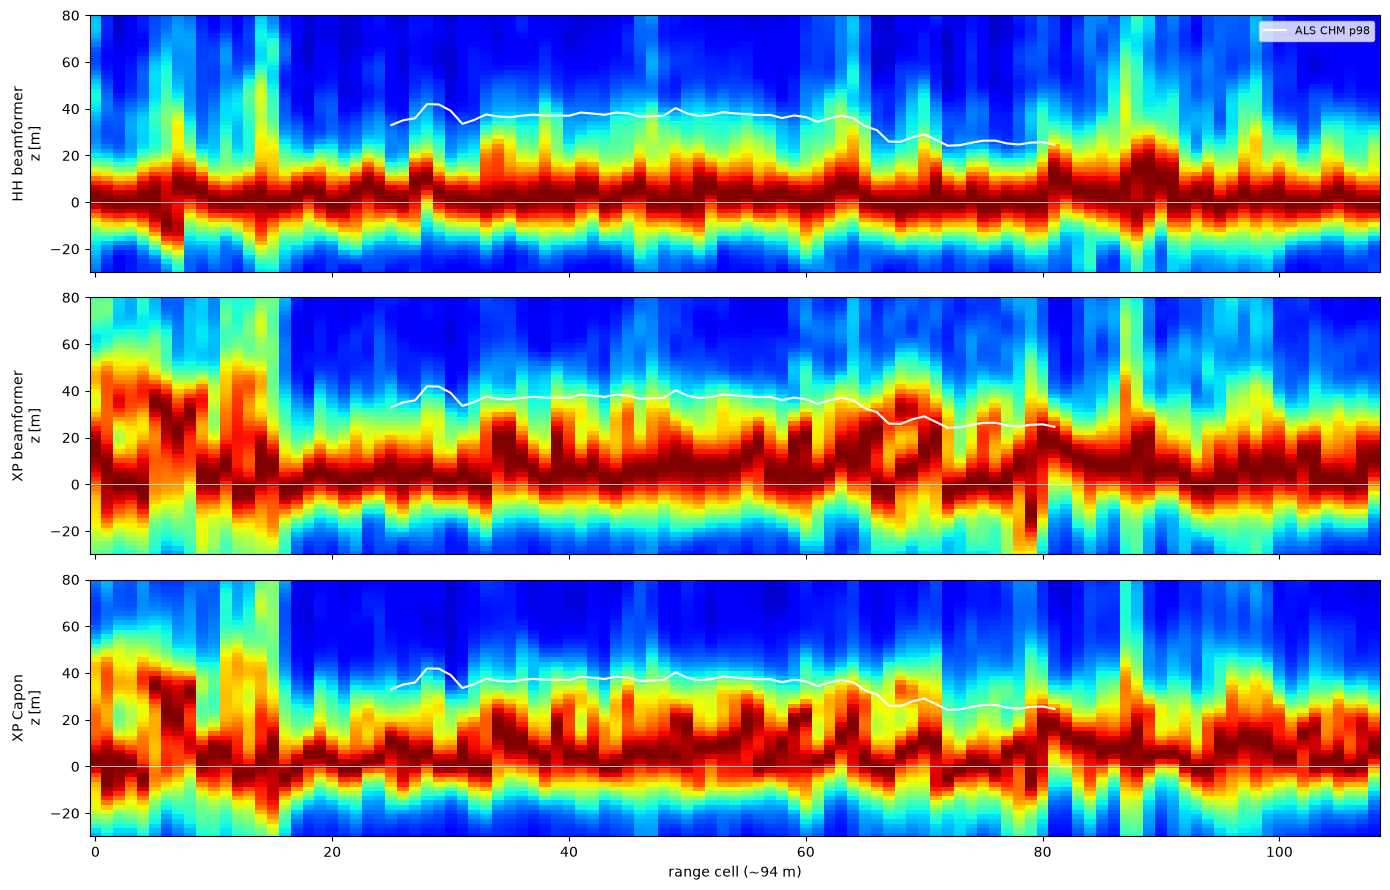

In [25]:
row = int(np.nanargmax(ok.sum(1)))
lines = {f"ALS {TOP}": (np.where(ok[row], ref[TOP][row], np.nan), "w-")}

fig, ax = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for a, key in zip(ax, [("HH", "beamformer"), ("XP", "beamformer"), ("XP", "Capon")]):
    transect(a, TOMO[key][row], lines, f"{key[0]} {key[1]}")
ax[0].legend(loc="upper right", fontsize=8); ax[-1].set_xlabel("range cell (~94 m)")

plt.tight_layout()
plt.show()

### F. Comparison with the pre-computed TOM cube (TOM_L1D)

In [26]:
def tom_l1d_dir():
    return next(WORKSHOP.glob("*/BIO_TP_TOM_L1D_*"))


def read_l1d_geometry(p):
    """Lat/lon of the TOM_L1D LUT nodes, the nodes' (az, rg) times, and the cube pixels' (az, rg) times."""
    with netCDF4.Dataset(next((p / "annotation").glob("*lut.nc"))) as f:
        f.set_auto_mask(False)
        g, t = f["geometry"], f["tomography"]
        times = lambda grp: [np.asarray(grp[v][:]) for v in grp.variables if v.lower().endswith(("azimuthtime", "rangetime"))]
        lat, lon = (np.where(g[v][:] == -9999, np.nan, g[v][:]) for v in ("latitude", "longitude"))
        return dict(lat=lat, lon=lon, node_t=times(g), pix_t=times(t))

def match_cells(lat, lon, G):
    """Cube pixel (row, col) for each cell: nearest LUT node by lat/lon, then the cube pixel at that node's time; distance [m]."""
    good = np.isfinite(G["lat"]) & np.isfinite(G["lon"])
    c = np.cos(np.deg2rad(np.nanmean(G["lat"])))                    # degrees of longitude are shorter
    ia, ir = np.where(good)
    q = np.c_[np.ravel(lat), np.ravel(lon) * c]
    fin = np.isfinite(q).all(1)
    dist, j = cKDTree(np.c_[G["lat"][good], G["lon"][good] * c]).query(np.where(fin[:, None], q, 0.0))

    # LUT nodes are coarser than the cube: node time -> cube pixel index
    row = np.clip(np.searchsorted(G["pix_t"][0], G["node_t"][0][ia[j]]), 0, G["pix_t"][0].size - 1)
    col = np.clip(np.searchsorted(G["pix_t"][1], G["node_t"][1][ir[j]]), 0, G["pix_t"][1].size - 1)
    shape = np.shape(lat)
    return dict(row=row.reshape(shape), col=col.reshape(shape), valid=fin.reshape(shape), dist_m=(dist * 111_320).reshape(shape))

def read_cube_at(p, M):
    """Cube profiles at the matched pixels: {pol: (az cell, rg cell, z)} (HV keyed 'XP') and the cube's z axis."""
    a = annot(next((p / "annotation").glob("*annot.xml")))
    pols = list(a["polarization"][:3])
    z_cube = float(a["minVerticalAxis"]) + float(a["verticalAxisStep"]) * np.arange(int(a["numberOfVerticalSamples"]))
    v = M["valid"]; r, c = M["row"][v], M["col"][v]

    # one slab over the cells' bounding box, then pick the matched pixels
    with netCDF4.Dataset(next(f for f in (p / "measurement").iterdir() if f.suffix == ".nc")) as f:
        slab = np.asarray(f["tomographicCubes"][r.min():r.max() + 1, c.min():c.max() + 1], "float32")
    slab[slab == -9999] = np.nan
    out = np.full((*v.shape, z_cube.size, len(pols)), np.nan, "float32")
    out[v] = slab[r - r.min(), c - c.min()]
    return {("XP" if pl == "HV" else pl): out[..., i] for i, pl in enumerate(pols)}, z_cube

In [27]:
L1D = tom_l1d_dir()
M = match_cells(lat_c, lon_c, read_l1d_geometry(L1D))
cube, z_cube = read_cube_at(L1D, M)
assert np.allclose(z_cube, z), "cube z axis differs from ours"

# the two sources, same cells, same z axis; ours = the cube's recipe (covariance beamformer)
PROFILES = {"L1C": {p: TOMO[(p, "beamformer, covariance")] for p in POLS},
            "L1D": cube}
print(f"{L1D.name[:40]}… · cell → cube pixel: median {np.nanmedian(M['dist_m'][ok]):.0f}m")

BIO_TP_TOM_L1D_20260211T224901_20260301T… · cell → cube pixel: median 27m


Comparison functions for pre-computed and processed `tomcubes`

In [28]:
def profile_r(P, Q):
    """Pearson r per cell between two sets of profiles (..., z)."""
    a = P - np.nanmean(P, -1, keepdims=True); b = Q - np.nanmean(Q, -1, keepdims=True)
    return np.nansum(a * b, -1) / np.sqrt(np.nansum(a * a, -1) * np.nansum(b * b, -1))


def best_shift(P, Q, z, max_shift_m=10.0):
    """Best r over vertical shifts of P against Q within ±max_shift_m, and that shift [m]."""
    L = int(round(max_shift_m / (z[1] - z[0])))
    r_at = lambda l: profile_r(P[..., l:], Q[..., :Q.shape[-1] - l]) if l >= 0 else profile_r(P[..., :l], Q[..., -l:])
    lags = np.arange(-L, L + 1)
    R = np.stack([r_at(l) for l in lags], -1)
    k = np.nanargmax(np.where(np.isfinite(R), R, -2), -1)
    return np.take_along_axis(R, k[..., None], -1)[..., 0], lags[k] * (z[1] - z[0])


def power_offset_db(P, Q):
    """10·log10 of the z-integrated power ratio P / Q per cell."""
    return 10 * np.log10(np.nansum(P, -1) / np.nansum(Q, -1))


def compare_profiles(A, B, mask):
    """Per pol: median r (and its 5th percentile), best-shift r and shift, power offset [dB] of source A against source B."""
    rows = {}
    for p in A:
        r0 = profile_r(norm(A[p]), norm(B[p]))
        rb, sh = best_shift(norm(A[p]), norm(B[p]), z)
        db = power_offset_db(A[p], B[p])[mask]
        rows[p] = dict(r=np.nanmedian(r0[mask]), r_p5=np.nanpercentile(r0[mask], 5), r_best=np.nanmedian(rb[mask]),
                       shift_m=np.nanmedian(sh[mask]), power_dB=np.nanmedian(db), power_IQR_dB=np.subtract(*np.nanpercentile(db, [75, 25])))
    return pd.DataFrame(rows).T.round(3)

In [29]:
compare_profiles(PROFILES["L1C"], PROFILES["L1D"], ok)

,r,r_p5,r_best,shift_m,power_dB,power_IQR_dB
HH,0.991,0.957,0.994,0.0,10.080,0.586
XP,0.988,0.942,0.991,0.0,10.063,0.445
VV,0.988,0.942,0.992,0.0,10.077,0.522


Comparing transects in §E with pre-computed tomogram transects

In [30]:
def plot_transects(sources, pols, row, lines):
    """One panel per (pol, source) along one row of cells."""
    keys = [(p, s) for p in pols for s in sources]
    fig, ax = plt.subplots(len(keys), 1, figsize=(14, 2.6 * len(keys)), sharex=True)
    for a, (p, s) in zip(ax, keys):
        transect(a, sources[s][p][row], lines, f"{s} {'HV' if s == 'L1D' and p == 'XP' else p}")
    ax[0].legend(loc="upper right", fontsize=8)
    ax[-1].set_xlabel("range cell (~94 m)")
    
    plt.tight_layout()
    plt.show()

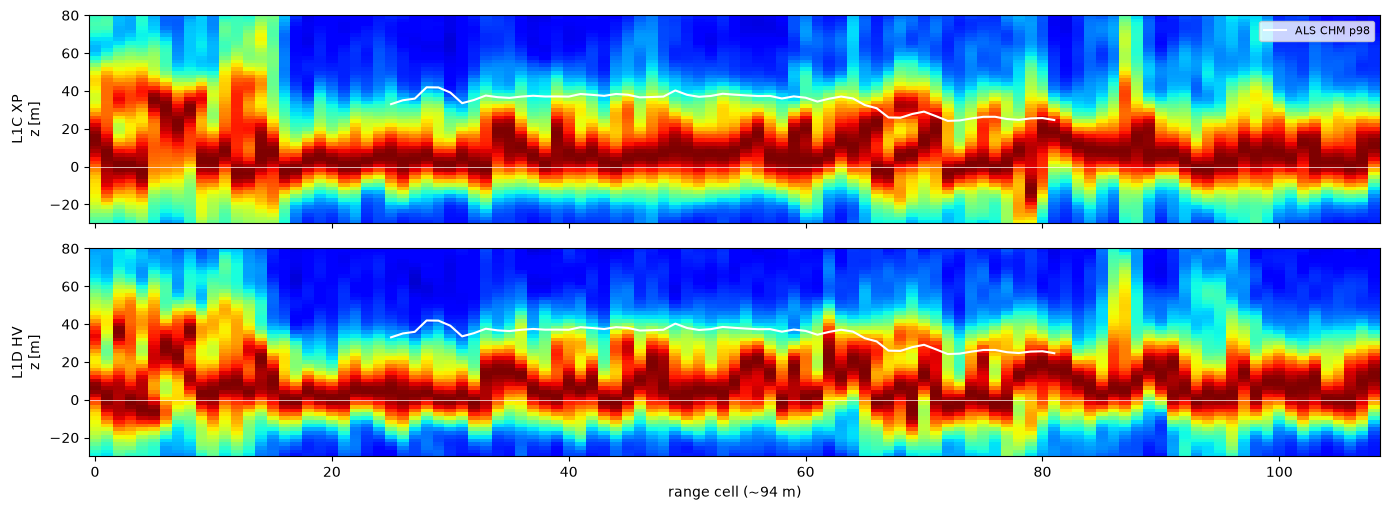

In [31]:
plot_transects(PROFILES, ("XP",), row, lines)

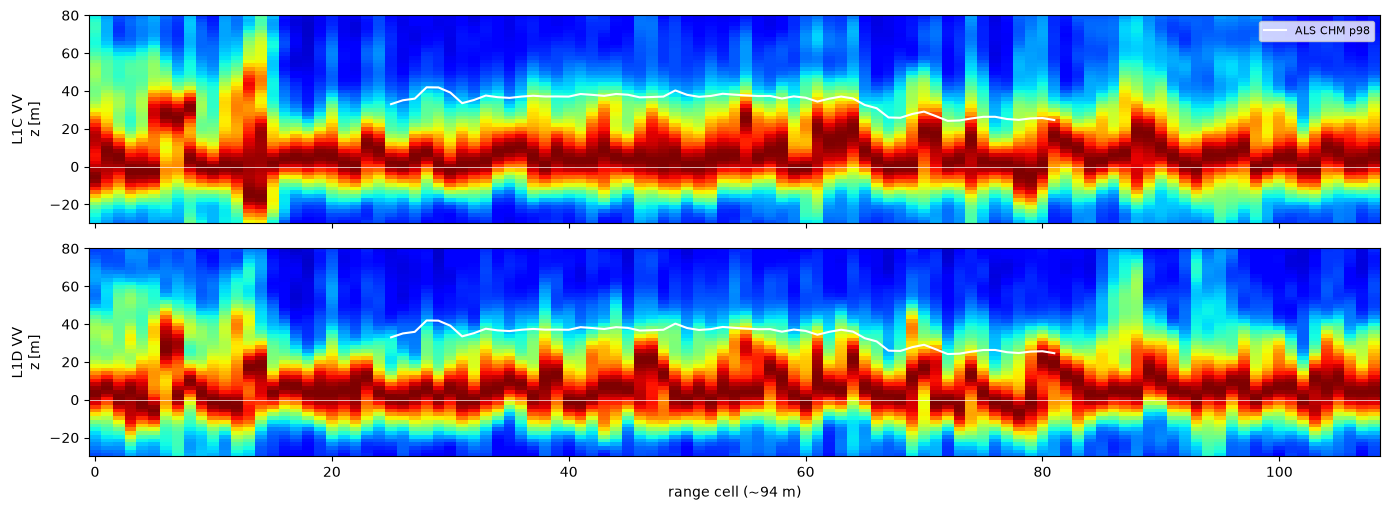

In [32]:
plot_transects(PROFILES, ("VV",), row, lines)

In [33]:
def plot_median_profiles(sources, sel_sets, pols=("HH", "XP")):
    """Median peak-normalised profile per source and pol, one panel per cell selection {label: mask}."""
    fig, ax = plt.subplots(1, len(sel_sets), figsize=(6 * len(sel_sets), 5), sharey=True)
    for a, (lab, sel) in zip(np.atleast_1d(ax), sel_sets.items()):
        for p, col in zip(pols, ("C0", "C3")):
            for s, ls in zip(sources, ("--", "-")):
                a.plot(np.nanmedian(norm(sources[s][p])[sel], 0), z, color=col, ls=ls, label=f"{s} {'HV' if s == 'L1D' and p == 'XP' else p}")
        a.axhline(np.nanmedian(ref[TOP][sel]), color="g", ls=":", label=f"ALS {TOP} median")
        a.axhline(0, color="k", lw=.5)
        a.set_ylim(-40, 80)
        a.set_xlabel("normalised power")
        a.set_title(f"{lab} (n={int(sel.sum())})")
    np.atleast_1d(ax)[0].set_ylabel("z [m]")
    np.atleast_1d(ax)[-1].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

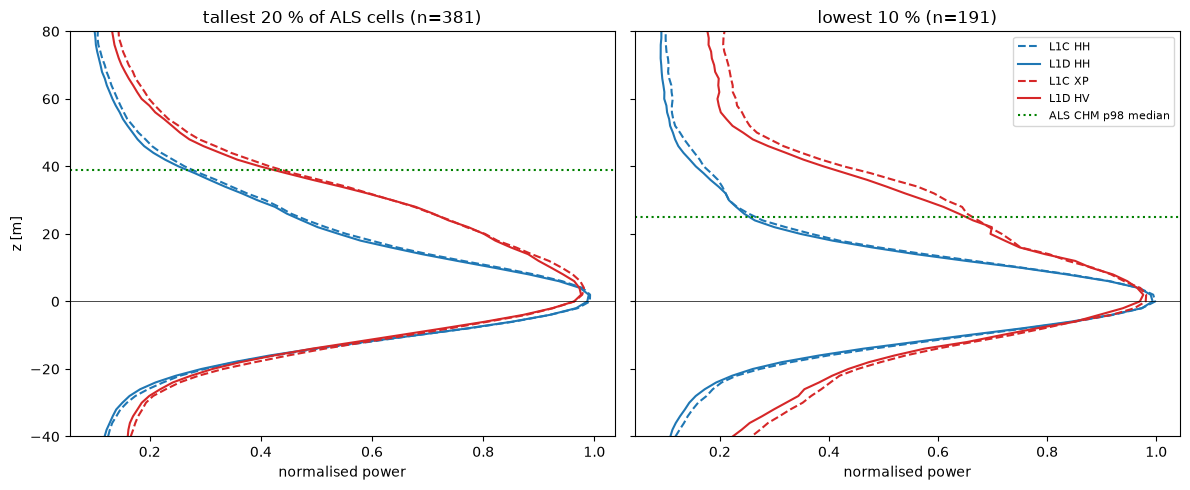

In [34]:
tall = ok & (ref[TOP] >= np.nanpercentile(ref[TOP][ok], 80))
low = ok & (ref[TOP] <= np.nanpercentile(ref[TOP][ok], 10))

plot_median_profiles(PROFILES, {"tallest 20 % of ALS cells": tall, "lowest 10 %": low})

### G. Deriving FH from both `tomocube`s

Current rule in the BPS processing pipeline proposes filtering height by an 80% cut off relative to the signal peak 

In [35]:
# BPS TFH's AUX values; override per call
TFH = dict(thr=0.8, zwin=(-10.0, 80.0), median=5, valid=(5.0, 100.0))

In [36]:
def threshold_top(P, z, thr=0.8, zwin=(-10.0, 80.0)):
    """BPS TFH's rule: the last height inside zwin where the profile drops from > thr x peak to ≤ thr x peak."""
    keep = (z >= zwin[0]) & (z <= zwin[1])
    Q = np.nan_to_num(P[..., keep])
    above = Q > thr * Q.max(-1, keepdims=True)
    drop = above & ~np.roll(above, -1, -1)
    drop[..., 0] = drop[..., -1] = False # edges never count as a drop
    last = np.where(drop.any(-1), drop.shape[-1] - 1 - np.argmax(drop[..., ::-1], -1), 0)
    return z[keep][last]

In [37]:
def slope_factor(slope, inc):
    """BPS TFH's slope correction"""
    return 1 - np.tan(slope) / np.tan(inc - slope)


def post_tfh(Hraw, slope, inc, data, median=5, valid=(5.0, 100.0), fill=-10.0):
    """Failures → fill, med x med filter, slope correction, valid range"""
    H = medfilt2d(np.where(np.isfinite(Hraw), Hraw, fill), median) * slope_factor(slope, inc)
    H[(H < valid[0]) | (H > valid[1]) | ~data] = np.nan
    return H


def tfh_map(P, thr=TFH["thr"], zwin=TFH["zwin"], median=TFH["median"], valid=TFH["valid"], offset=None):
    """Profiles (az cell, rg cell, z): TFH-style height map at the evaluation cells.
    offset: per-cell height of z = 0 above the true ground [m], added to the raw height before post-processing (G2)."""
    Hraw = threshold_top(P, z, thr, zwin)
    if offset is not None:
        Hraw = Hraw + offset
    return post_tfh(Hraw, slope_c, inc_c, data_cells, median=median, valid=valid)

In [ ]:
# Comparison of derived height, by different proposed processing steps: 80% ToC cutoff, median smoothing, SKP correction

Hraw = threshold_top(PROFILES["L1C"]["XP"], z)
Hmed = medfilt2d(np.where(np.isfinite(Hraw), Hraw, -10.0), 5)
steps = {
    "1-3 raw threshold top": np.where(data_cells, Hraw, np.nan), 
    "4 med 5x5": np.where(data_cells, Hmed, np.nan),
    "5-6 slope corr. + valid range": tfh_map(PROFILES["L1C"]["XP"])
}

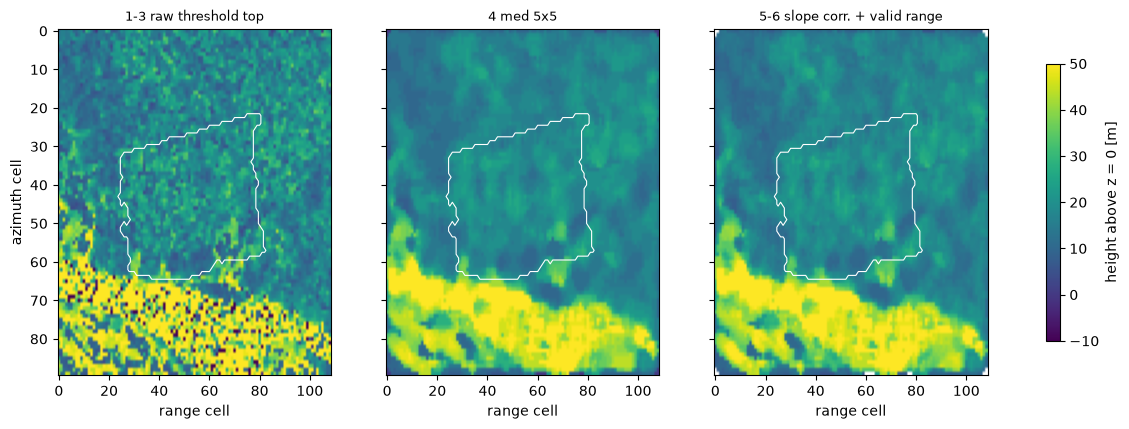

slope factor at the cells: p5 / p50 / p95 = [0.916 1.    1.068]


In [39]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for a, (k, y) in zip(ax, steps.items()):
    im = a.imshow(y, vmin=-10, vmax=50, cmap="viridis", aspect="auto"); a.contour(ok, [.5], colors="w", linewidths=.8)
    a.set_title(k, fontsize=9)
    a.set_xlabel("range cell")
ax[0].set_ylabel("azimuth cell")
fig.colorbar(im, ax=ax, shrink=.8, label="height above z = 0 [m]")
plt.show()

print("slope factor at the cells: p5 / p50 / p95 =", np.round(np.nanpercentile(slope_factor(slope_c, inc_c)[data_cells], [5, 50, 95]), 3))

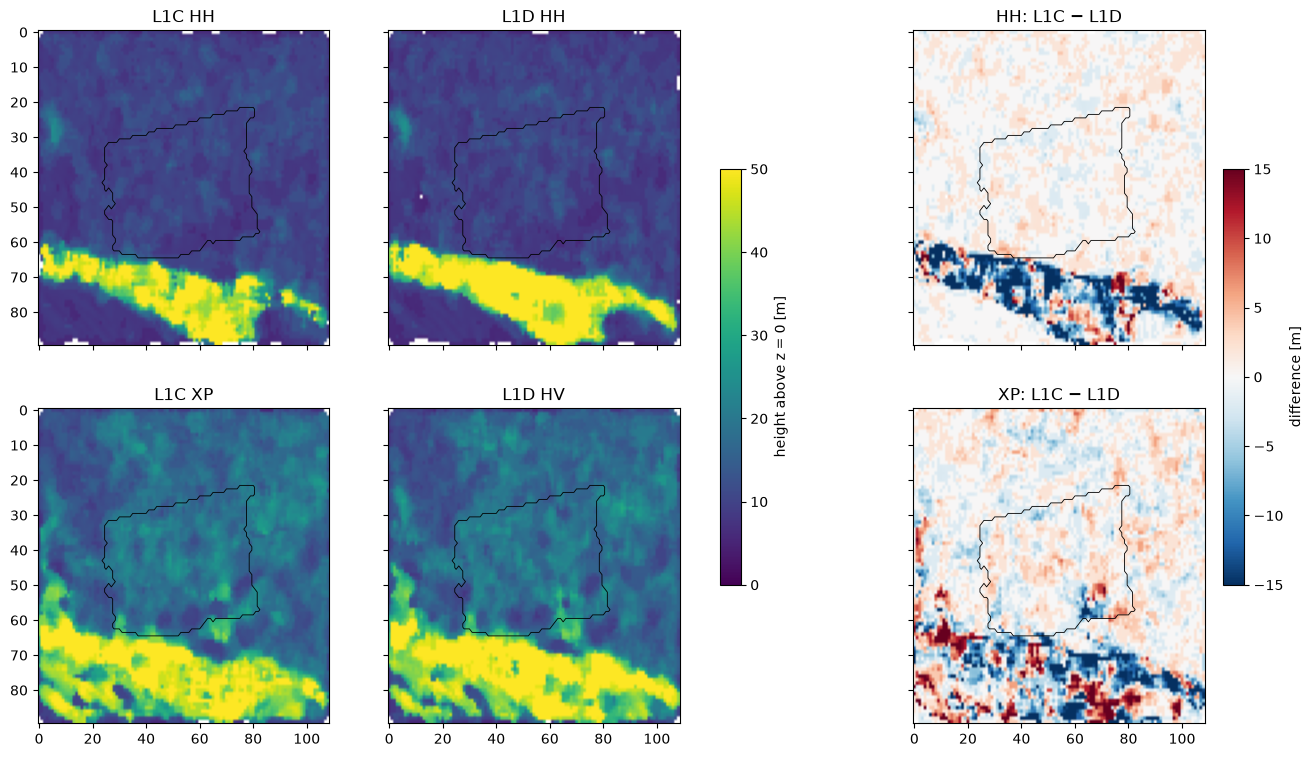

In [41]:
label = lambda s, p: f"{s} {'HV' if s == 'L1D' and p == 'XP' else p}"
HEIGHTS = {(s, p): tfh_map(PROFILES[s][p]) for s in PROFILES for p in ("HH", "XP")}

fig, ax = plt.subplots(2, 3, figsize=(16, 9), sharex=True, sharey=True)
for i, p in enumerate(("HH", "XP")):
    for j, s in enumerate(PROFILES):
        im = ax[i, j].imshow(HEIGHTS[(s, p)], vmin=0, vmax=50, cmap="viridis", aspect="auto"); ax[i, j].set_title(label(s, p))
    d = HEIGHTS[("L1C", p)] - HEIGHTS[("L1D", p)]
    im2 = ax[i, 2].imshow(d, vmin=-15, vmax=15, cmap="RdBu_r", aspect="auto"); ax[i, 2].set_title(f"{p}: L1C − L1D")
for a in ax.flat:
    a.contour(ok, [.5], colors="k", linewidths=.6)
fig.colorbar(im, ax=ax[:, :2], shrink=.6, label="height above z = 0 [m]"); fig.colorbar(im2, ax=ax[:, 2], shrink=.6, label="difference [m]")
plt.show()

### H. Comparison with Reference ALS

In [42]:
def score(y, mask, ref=ref, top=TOP):
    """n, r, bias, RMSE against ref[top], and where on the reference ladder the mean bias crosses zero."""
    m = mask & np.isfinite(y)
    b = np.array([np.mean(y[m] - ref[k][m]) for k in ref])
    i = int(np.argmax(b < 0)) if (b < 0).any() else None
    names = list(ref)
    match = f"> {names[-1]}" if i is None else f"< {names[0]}" if i == 0 else f"{names[i - 1]}…{names[i]}"
    x = ref[top][m]
    return dict(n=int(m.sum()), r=round(np.corrcoef(x, y[m])[0, 1], 2), bias=round(np.mean(y[m] - x), 1),
                rmse=round(np.sqrt(np.mean((y[m] - x) ** 2)), 1), matches=match)

def ladder_bias(y, mask, ref=ref):
    """Mean bias of y against each reference rung."""
    m = mask & np.isfinite(y)
    return {k: np.mean(y[m] - ref[k][m]) for k in ref}

Suspecting a terrain effect / flooded understoreys w.r.t the higher r2 between HH CHM vs HV

In [43]:
MAPS = {label(s, p): H for (s, p), H in HEIGHTS.items()}

closed = ok & (A["cover"] >= 0.8)
pd.concat({"all ALS cells": pd.DataFrame({k: score(y, ok) for k, y in MAPS.items()}).T,
           "closed canopy": pd.DataFrame({k: score(y, closed) for k, y in MAPS.items()}).T})

n     r  bias  rmse     matches
all ALS cells L1C HH  1902  0.37 -24.6  25.0  < CHM mean
              L1C XP  1902  0.14 -15.5  16.6  < CHM mean
              L1D HH  1902  0.34 -24.8  25.2  < CHM mean
              L1D HV  1902  0.12 -15.5  16.7  < CHM mean
closed canopy L1C HH  1837  0.33 -24.9  25.2  < CHM mean
              L1C XP  1837  0.06 -15.8  16.8  < CHM mean
              L1D HH  1837   0.3 -25.1  25.5  < CHM mean
              L1D HV  1837  0.05 -15.9  16.9  < CHM mean

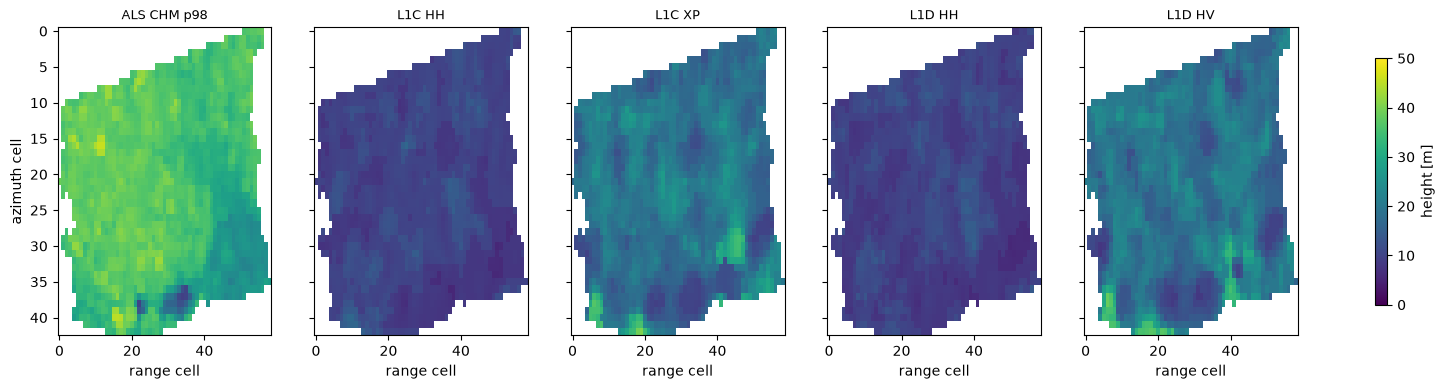

In [44]:
fig, ax = plt.subplots(1, len(MAPS) + 1, figsize=(4 * (len(MAPS) + 1), 4), sharey=True)
inside = lambda y: np.where(ok, y, np.nan)
rr, cc = np.where(ok)
crop = (slice(rr.min(), rr.max() + 1), slice(cc.min(), cc.max() + 1))

for a, (k, y) in zip(ax, [(f"ALS {TOP}", ref[TOP]), *MAPS.items()]):
    im = a.imshow(inside(y)[crop], vmin=0, vmax=50, cmap="viridis", aspect="auto")
    a.set_title(k, fontsize=9)
    a.set_xlabel("range cell")
ax[0].set_ylabel("azimuth cell"); fig.colorbar(im, ax=ax, shrink=.8, label="height [m]"); plt.show()